**Data Loading and Understanding**

In [98]:
import pandas as pd

In [99]:
df=pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [100]:
#Check the dataset shape
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [101]:
#Check the column names
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [102]:
#Check the data types
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

In [103]:
#Check missing values
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [104]:
#Check Total Charges
df['TotalCharges'].value_counts().head(10)

TotalCharges
         11
20.2     11
19.75     9
20.05     8
19.9      8
19.65     8
45.3      7
19.55     7
20.15     6
20.25     6
Name: count, dtype: int64

In [105]:
#Check the Total charges data type
df['TotalCharges'].dtype

dtype('O')

In [106]:
#Convert total charges to numeric
df['TotalCharges']=pd.to_numeric(df['TotalCharges'], errors='coerce')

In [107]:
#Check missing values again
df['TotalCharges'].isnull().sum()

11

In [108]:
df[df['TotalCharges'].isnull()][['tenure','MonthlyCharges','TotalCharges','Churn']]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


In [109]:
#check the 11 missing records
df[df['TotalCharges'].isnull()][['tenure','MonthlyCharges','TotalCharges','Churn']]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


In [110]:
#Fill missiing TotalCharges
df['TotalCharges']=df['TotalCharges'].fillna(0)

In [111]:
#Verify
df['TotalCharges'].isnull().sum()

0

In [112]:
df['TotalCharges'].dtype

dtype('float64')

In [113]:
#Check for duplicate customers
df['customerID'].duplicated().sum()

0

In [114]:
df.duplicated().sum()

0

In [115]:
#Check the target variable
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [116]:
df['Churn'].value_counts(normalize=True)*100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [117]:
#Check numerical columns
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [118]:
#Check categorical colimns
categorical_columns = df.select_dtypes(include='object').columns

for col in categorical_columns:
    print(f'\n{col}:')
    print(df[col].unique())


customerID:
['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']

gender:
['Female' 'Male']

Partner:
['Yes' 'No']

Dependents:
['No' 'Yes']

PhoneService:
['No' 'Yes']

MultipleLines:
['No phone service' 'No' 'Yes']

InternetService:
['DSL' 'Fiber optic' 'No']

OnlineSecurity:
['No' 'Yes' 'No internet service']

OnlineBackup:
['Yes' 'No' 'No internet service']

DeviceProtection:
['No' 'Yes' 'No internet service']

TechSupport:
['No' 'Yes' 'No internet service']

StreamingTV:
['No' 'Yes' 'No internet service']

StreamingMovies:
['No' 'Yes' 'No internet service']

Contract:
['Month-to-month' 'One year' 'Two year']

PaperlessBilling:
['Yes' 'No']

PaymentMethod:
['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']

Churn:
['No' 'Yes']


In [119]:
#Check categorical column counts
for col in categorical_columns:
    print(col,':',df[col].nunique())
    

customerID : 7043
gender : 2
Partner : 2
Dependents : 2
PhoneService : 2
MultipleLines : 3
InternetService : 3
OnlineSecurity : 3
OnlineBackup : 3
DeviceProtection : 3
TechSupport : 3
StreamingTV : 3
StreamingMovies : 3
Contract : 3
PaperlessBilling : 2
PaymentMethod : 4
Churn : 2


In [120]:
#Check the numerical columns
numerical_columns=df.select_dtypes(include=['int64','float64']).columns
print(numerical_columns)

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')


In [121]:
print('Number of numerical columns:', len(numerical_columns))

Number of numerical columns: 4


In [122]:
#Check numerical feature distributions
for col in numerical_columns:
    print(f'\n{col}')
    print(df[col].describe())


SeniorCitizen
count    7043.000000
mean        0.162147
std         0.368612
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         1.000000
Name: SeniorCitizen, dtype: float64

tenure
count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64

MonthlyCharges
count    7043.000000
mean       64.761692
std        30.090047
min        18.250000
25%        35.500000
50%        70.350000
75%        89.850000
max       118.750000
Name: MonthlyCharges, dtype: float64

TotalCharges
count    7043.000000
mean     2279.734304
std      2266.794470
min         0.000000
25%       398.550000
50%      1394.550000
75%      3786.600000
max      8684.800000
Name: TotalCharges, dtype: float64


In [123]:
#Check numerical features against Churn
df.groupby('Churn')['tenure'].mean()

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64

In [124]:
df.groupby('Churn')['MonthlyCharges'].mean()

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64

In [125]:
df.groupby('Churn')['TotalCharges'].mean()

Churn
No     2549.911442
Yes    1531.796094
Name: TotalCharges, dtype: float64

In [126]:
#Analyze categorical features
df.groupby('Contract')['Churn'].value_counts(normalize=True)*100

Contract        Churn
Month-to-month  No       57.290323
                Yes      42.709677
One year        No       88.730482
                Yes      11.269518
Two year        No       97.168142
                Yes       2.831858
Name: proportion, dtype: float64

In [127]:
#Analyze InternetService vs Churn
df.groupby('InternetService')['Churn'].value_counts(normalize=True)*100

InternetService  Churn
DSL              No       81.040892
                 Yes      18.959108
Fiber optic      No       58.107235
                 Yes      41.892765
No               No       92.595020
                 Yes       7.404980
Name: proportion, dtype: float64

In [128]:
#PaymentMethod vs Churn
df.groupby('PaymentMethod')['Churn'].value_counts(normalize=True)*100

PaymentMethod              Churn
Bank transfer (automatic)  No       83.290155
                           Yes      16.709845
Credit card (automatic)    No       84.756899
                           Yes      15.243101
Electronic check           No       54.714588
                           Yes      45.285412
Mailed check               No       80.893300
                           Yes      19.106700
Name: proportion, dtype: float64

In [129]:
#Partner vs Churn
df.groupby('Partner')['Churn'].value_counts(normalize=True)*100

Partner  Churn
No       No       67.042021
         Yes      32.957979
Yes      No       80.335097
         Yes      19.664903
Name: proportion, dtype: float64

In [130]:
#Dependents vs Churn
df.groupby('Dependents')['Churn'].value_counts(normalize=True)*100

Dependents  Churn
No          No       68.720860
            Yes      31.279140
Yes         No       84.549763
            Yes      15.450237
Name: proportion, dtype: float64

In [131]:
#PaperlessBilling vs Churn
df.groupby('PaperlessBilling')['Churn'].value_counts(normalize=True)*100

PaperlessBilling  Churn
No                No       83.669916
                  Yes      16.330084
Yes               No       66.434908
                  Yes      33.565092
Name: proportion, dtype: float64

In [132]:
#PhoneService vs Churn
df.groupby('PhoneService')['Churn'].value_counts(normalize=True)*100

PhoneService  Churn
No            No       75.073314
              Yes      24.926686
Yes           No       73.290363
              Yes      26.709637
Name: proportion, dtype: float64

In [133]:
#MultipleLines vs Churn
df.groupby('MultipleLines')['Churn'].value_counts(normalize=True)*100

MultipleLines     Churn
No                No       74.955752
                  Yes      25.044248
No phone service  No       75.073314
                  Yes      24.926686
Yes               No       71.390104
                  Yes      28.609896
Name: proportion, dtype: float64

In [134]:
#OnlineSecurity vs Churn
df.groupby('OnlineSecurity')['Churn'].value_counts(normalize=True)*100

OnlineSecurity       Churn
No                   No       58.233276
                     Yes      41.766724
No internet service  No       92.595020
                     Yes       7.404980
Yes                  No       85.388806
                     Yes      14.611194
Name: proportion, dtype: float64

In [135]:
#OnlineBackup vs Churn
df.groupby('OnlineBackup')['Churn'].value_counts(normalize=True)*100

OnlineBackup         Churn
No                   No       60.071244
                     Yes      39.928756
No internet service  No       92.595020
                     Yes       7.404980
Yes                  No       78.468506
                     Yes      21.531494
Name: proportion, dtype: float64

In [136]:
#DeviceProtection
df.groupby('DeviceProtection')['Churn'].value_counts(normalize=True)*100

DeviceProtection     Churn
No                   No       60.872375
                     Yes      39.127625
No internet service  No       92.595020
                     Yes       7.404980
Yes                  No       77.497936
                     Yes      22.502064
Name: proportion, dtype: float64

In [137]:
#TechSupport
df.groupby('TechSupport')['Churn'].value_counts(normalize=True)*100

TechSupport          Churn
No                   No       58.364526
                     Yes      41.635474
No internet service  No       92.595020
                     Yes       7.404980
Yes                  No       84.833659
                     Yes      15.166341
Name: proportion, dtype: float64

In [138]:
#check the StreamingTV:
df.groupby('StreamingTV')['Churn'].value_counts(normalize=True)*100

StreamingTV          Churn
No                   No       66.476868
                     Yes      33.523132
No internet service  No       92.595020
                     Yes       7.404980
Yes                  No       69.929812
                     Yes      30.070188
Name: proportion, dtype: float64

In [139]:
df.groupby('StreamingMovies')['Churn'].value_counts(normalize=True)*100

StreamingMovies      Churn
No                   No       66.319569
                     Yes      33.680431
No internet service  No       92.595020
                     Yes       7.404980
Yes                  No       70.058565
                     Yes      29.941435
Name: proportion, dtype: float64

In [140]:
df.groupby('gender')['Churn'].value_counts(normalize=True)*100

gender  Churn
Female  No       73.079128
        Yes      26.920872
Male    No       73.839662
        Yes      26.160338
Name: proportion, dtype: float64

In [141]:
df.groupby('SeniorCitizen')['Churn'].value_counts(normalize=True)*100

SeniorCitizen  Churn
0              No       76.393832
               Yes      23.606168
1              No       58.318739
               Yes      41.681261
Name: proportion, dtype: float64

**Exploratory Data Analysis(EDA)**

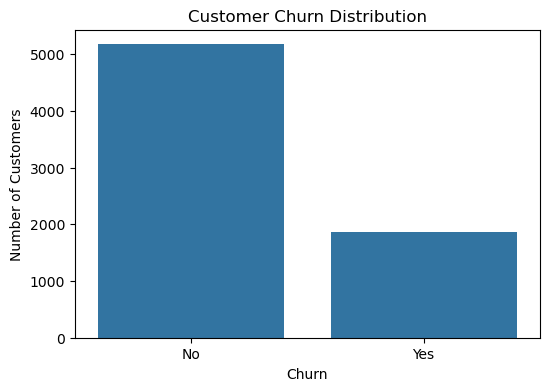

'Insights:\n\n- The dataset is imbalanced.\n\n- Most customers have not churned.\n\n- A smaller percentage of customers have churned.\n\n- Model evaluation should focus on Precision, Recall, F1-Score, and ROC-AUC, not just Accuracy.\n\nNo = Customer stayed with the company.\nYes = Customer left the company (churned).\n'

In [143]:
#Churn Distribution
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))

sns.countplot(data=df, x='Churn')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')

plt.show()

'''Insights:

- The dataset is imbalanced.

- Most customers have not churned.

- A smaller percentage of customers have churned.

- Model evaluation should focus on Precision, Recall, F1-Score, and ROC-AUC, not just Accuracy.

No = Customer stayed with the company.
Yes = Customer left the company (churned).
'''


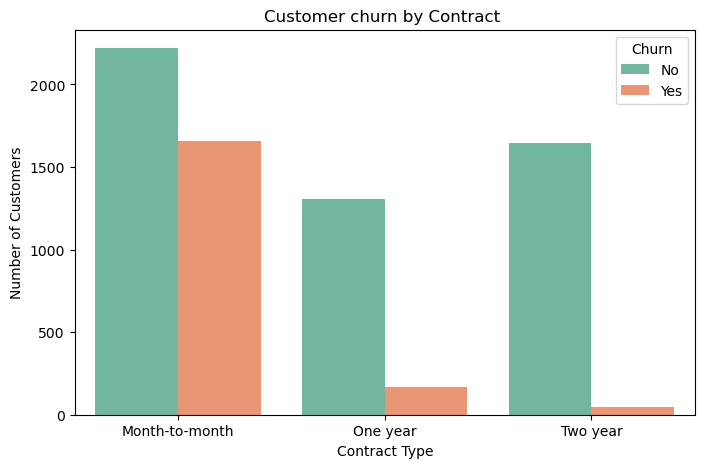

'Insights\nContract type has a significant impact on customer churn.\nCustomers with month-to-month contracts tend to churn more frequently.\nCustomers with one-year and two-year contracts generally show better retention.\nContract type is likely to be an important predictor in the churn prediction model.'

In [144]:
#Churn by Contract Type

plt.figure(figsize=(8,5))

sns.countplot(data=df,x='Contract',hue='Churn',palette='Set2')

plt.title('Customer churn by Contract ')

plt.xlabel('Contract Type')

plt.ylabel('Number of Customers')

plt.show()

'''Insights
Contract type has a significant impact on customer churn.
Customers with month-to-month contracts tend to churn more frequently.
Customers with one-year and two-year contracts generally show better retention.
Contract type is likely to be an important predictor in the churn prediction model.'''

'Insights\nChurn rates vary across internet service types.\nCertain internet service categories appear to have a higher number of churned customers.\nInternet service is likely to be an important feature for predicting customer churn.\nThe company may need to investigate service quality and customer satisfaction for high-churn service categories.'

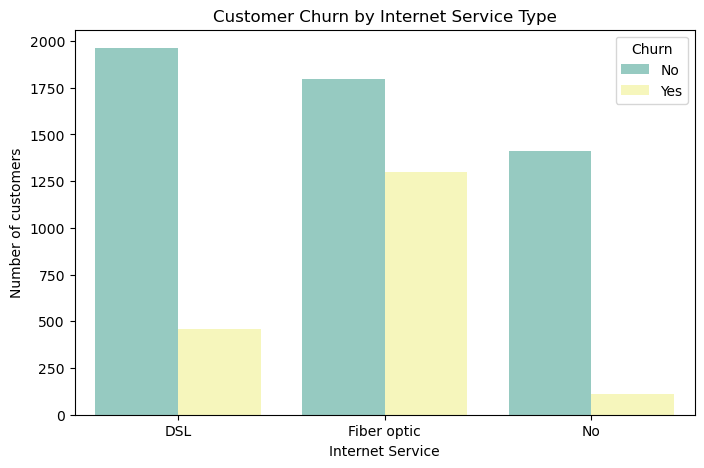

In [145]:
#Churn by Internet Service Type

plt.figure(figsize=(8,5))

sns.countplot(data=df,x='InternetService',hue='Churn',palette='Set3')

plt.title('Customer Churn by Internet Service Type')

plt.xlabel('Internet Service')

plt.ylabel('Number of customers')

plt.show

'''Insights
Churn rates vary across internet service types.
Certain internet service categories appear to have a higher number of churned customers.
Internet service is likely to be an important feature for predicting customer churn.
The company may need to investigate service quality and customer satisfaction for high-churn service categories.'''

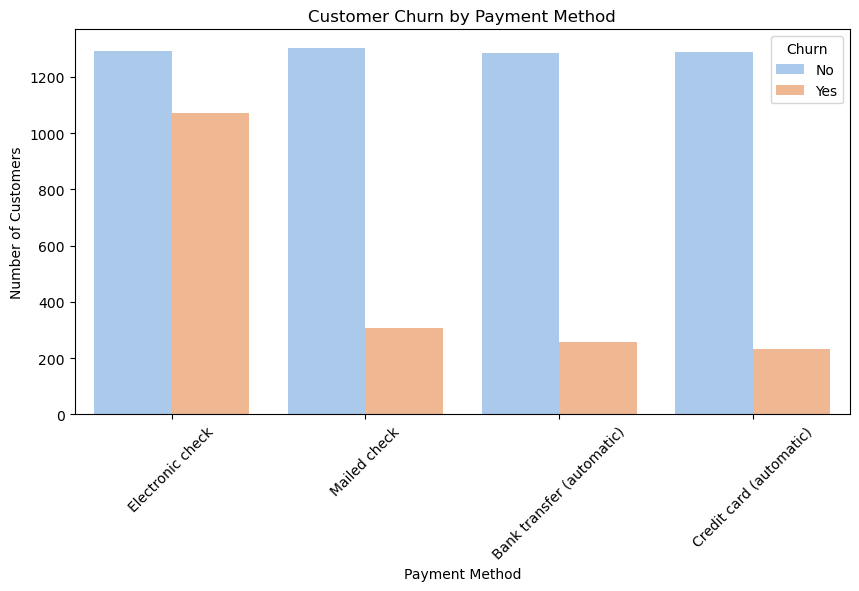

'Insights\nCustomer churn varies across payment methods.\nSome payment methods show a larger number of churned customers.\nAutomatic payment methods generally indicate'

In [146]:
#Churn by Payment Method

plt.figure(figsize=(10,5))

sns.countplot(data=df,x='PaymentMethod',hue='Churn',palette='pastel')

plt.title('Customer Churn by Payment Method')

plt.xlabel('Payment Method')

plt.ylabel('Number of Customers')

plt.xticks(rotation=45)

plt.show()

'''Insights
Customer churn varies across payment methods.
Some payment methods show a larger number of churned customers.
Automatic payment methods generally indicate'''

C:\Users\Pratik\AppData\Local\Temp\ipykernel_10680\837824482.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df,x='Churn',y='tenure',palette={'No':'skyblue','Yes':'salmon'})


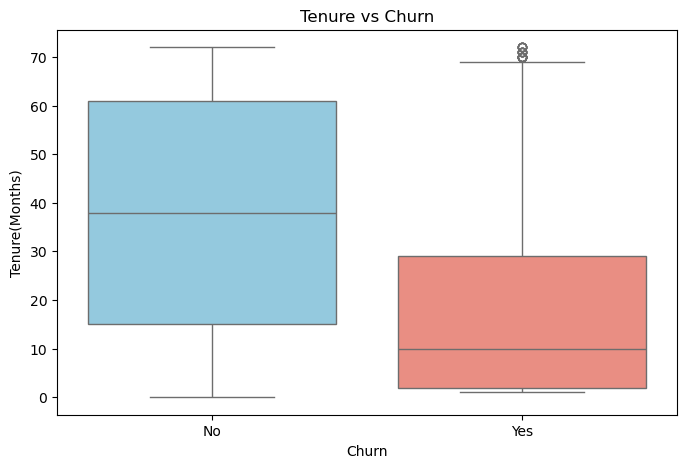

'Insights\nCustomers who churn typically have lower tenure compared to customers who stay.\nThe median tenure of churned customers is significantly lower than that of retained customers.\nLong-term customers are generally more loyal and have lower churn rates.\nA small number of long-term customers also churn, indicating that tenure alone does not fully explain customer behavior.\nTenure appears to be one of the strongest predictors of customer churn.'

In [147]:
#Tenure vs Churn

plt.figure(figsize=(8,5))

sns.boxplot(data=df,x='Churn',y='tenure',palette={'No':'skyblue','Yes':'salmon'})

plt.title('Tenure vs Churn')

plt.xlabel('Churn')

plt.ylabel('Tenure(Months)')

plt.show()

'''Insights
Customers who churn typically have lower tenure compared to customers who stay.
The median tenure of churned customers is significantly lower than that of retained customers.
Long-term customers are generally more loyal and have lower churn rates.
A small number of long-term customers also churn, indicating that tenure alone does not fully explain customer behavior.
Tenure appears to be one of the strongest predictors of customer churn.'''

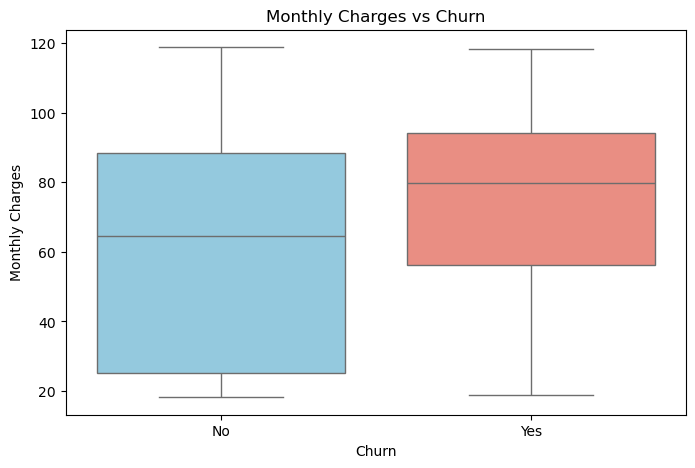

'Insights\nMonthly charges show a relationship with customer churn.\nCustomers with higher monthly charges tend to churn more frequently.\nPricing may influence customer retention decisions.\nMonthlyCharges is expected to be an important feature for churn prediction models.'

In [148]:
#Monthly Charges vs Churn

plt.figure(figsize=(8,5))

sns.boxplot(data=df,x='Churn',y='MonthlyCharges',hue='Churn',palette={'No':'skyblue','Yes':'salmon'},legend=False)

plt.title('Monthly Charges vs Churn')

plt.xlabel('Churn')

plt.ylabel('Monthly Charges')

plt.show()

'''Insights
Monthly charges show a relationship with customer churn.
Customers with higher monthly charges tend to churn more frequently.
Pricing may influence customer retention decisions.
MonthlyCharges is expected to be an important feature for churn prediction models.'''

**Data Cleaning and preparation**

In [150]:
#Convert the total charges to numeric

#Create copy of the dataset
df_ml = df.copy()

#Convert total charges to numeric
df_ml['TotalCharges'] = pd.to_numeric(
    df_ml['TotalCharges'],
    errors='coerce'
)

#Check missing values
print('Missing TotalCharges:', df_ml['TotalCharges'].isnull().sum())

Missing TotalCharges: 0


In [151]:
#Check rows with missing TotalCharges
print(df_ml[df_ml['TotalCharges'].isnull()][
      ['tenure','MonthlyCharges','TotalCharges']
])

Empty DataFrame
Columns: [tenure, MonthlyCharges, TotalCharges]
Index: []


In [152]:
#Check the data types
df_ml.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [153]:
#Check the target column

#Check churn values
print(df_ml['Churn'].value_counts())

#Check churn percentages
print(df_ml['Churn'].value_counts(normalize=True)*100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [154]:
#Seprate featutures (X) and Target (y)

#Create X and y

#Remove customerID because it is an identifier
df_ml = df_ml.drop(columns=['customerID'])

#Seprate input features and target
X = df_ml.drop(columns=['Churn'])
y = df_ml['Churn']

#Display names
print('Features shape:', X.shape)
print('Target shape:', y.shape)

#Display target values
print('\nTarget values:')
print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)

Target values:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [155]:
#Split the data into Training(80%) and Testing(20%) Sets

from sklearn.model_selection import train_test_split

#split the dataset
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

#Chcek dataset sizes
print('Training features:',X_train.shape)
print('Testing features:',X_test.shape)

print('Training target:',y_train.shape)
print('Testing target:',y_test.shape)

Training features: (5634, 19)
Testing features: (1409, 19)
Training target: (5634,)
Testing target: (1409,)


In [156]:
#identify the numerical and categorical columns
numerical_features = X_train.select_dtypes(include=['int64','float64']).columns.tolist()

#identify categorical columns
categorical_features = X_train.select_dtypes(include=['object']).columns.tolist()

print('Numerical features:')
print(numerical_features)

print('\nCategorical features:')
print(categorical_features)

print('\nNumber of numerical features',len(numerical_features))
print('Number of categorical features',len(categorical_features))

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of numerical features 4
Number of categorical features 15


In [157]:
#Build the processing pipeline

#Import the required libraries

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

In [158]:
#Create the numerical preprocessing pipeline

numerical_pipeline = Pipeline(steps=[
    ('imputer',SimpleImputer(strategy='median')),
    ('scaler',StandardScaler())
])

In [159]:
#Create the categorical preprocessing pipeline
categorical_pipeline = Pipeline(
    steps=[
        ('imputer',SimpleImputer(strategy='most_frequent')),
        ('encoder',OneHotEncoder(handle_unknown='ignore'))
    ]
)

In [160]:
#Combine both pipelines

preprocessor = ColumnTransformer(
    transformers=[
        ('num',numerical_pipeline,numerical_features),
        ('cat',categorical_pipeline,categorical_features)
    ]
)

print('Preprocessing pipeline created successfully')

Preprocessing pipeline created successfully


**Train the machine learning model**

In [162]:
#import logistic regression
from sklearn.linear_model import LogisticRegression

In [163]:
#create the complete model pipeline
logistic_model = Pipeline(
    steps=[
        ('preprocessor',preprocessor),
        ('classifier',LogisticRegression(max_iter=1000,random_state=42))
    ]
)

print('Logistic Regression pipeline created successfully')

Logistic Regression pipeline created successfully


In [164]:
#Train the model
logistic_model.fit(X_train,y_train)

print('Model training completed successfully')

Model training completed successfully


In [165]:
#Make predictions

#Predict churn on unseen test data
y_pred = logistic_model.predict(X_test)

#Display the first 10 predictions
print('Predictions:',y_pred[:10])

print('\nActual values:')
print(y_test.iloc[:10].values)

Predictions: ['No' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No']

Actual values:
['No' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes']


**Evaluate the machine learning model**

In [167]:
#import the evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [168]:
#calculate the evluation metrics
accuracy = accuracy_score(y_test,y_pred)

precision = precision_score(
    y_test,y_pred,pos_label='Yes'
)

recall = recall_score(
    y_test,y_pred,pos_label='Yes'
)

f1 = f1_score(
    y_test,y_pred,pos_label='Yes'
)

#Display the results
print('Logistic Regression Model Evaluation')
print('-----------------------------------')
print(f'Accuracy: {accuracy:.4f}')
print(f'Precision: {precision:.4f}')
print(f'Recall: {recall:.4f}')
print(f'F1-Score: {f1:.4f}')

Logistic Regression Model Evaluation
-----------------------------------
Accuracy: 0.8055
Precision: 0.6572
Recall: 0.5588
F1-Score: 0.6040


In [169]:
#Generate confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['No','Yes']
)

print('Confusion Matrix:')
print(cm)

Confusion Matrix:
[[926 109]
 [165 209]]


In [170]:
#generate the classification report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



**Train the Random Forest Model**

In [172]:
#import Random Forest 
from sklearn.ensemble import RandomForestClassifier

In [173]:
#Create the random forest pipeline
rf_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight='balanced',
            n_jobs=-1
        ))
    ]
)

print('Random Forest pipeline created successfully')

Random Forest pipeline created successfully


In [174]:
#Train the model
rf_model.fit(X_train,y_train)

print('Random Forest training completed successfully!')

Random Forest training completed successfully!


In [175]:
#Make predictions
rf_pred = rf_model.predict(X_test)

print('First 10 predictions:')
print(rf_pred[:10])

print('\nFirst 10 actual values:')
print(y_test.iloc[:10].values)

First 10 predictions:
['No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No']

First 10 actual values:
['No' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes']


In [176]:
#evaluate the random forest model

#calculate the metrics
rf_accuracy = accuracy_score(y_test,rf_pred)

rf_precision = precision_score(
    y_test,rf_pred,pos_label='Yes'
)

rf_recall = recall_score(
    y_test,rf_pred,pos_label='Yes'
)

rf_f1 = f1_score(
    y_test,rf_pred,pos_label='Yes'
)

#Display results
print('Random Forest Model Evaluation')
print('--------------------------------')
print(f'Accuracy: {rf_accuracy:.4f}')
print(f'Precision: {rf_precision:.4f}')
print(f'Recall: {rf_recall:.4f}')
print(f'F1-Score: {rf_f1:.4f}')

Random Forest Model Evaluation
--------------------------------
Accuracy: 0.7828
Precision: 0.6189
Recall: 0.4733
F1-Score: 0.5364


In [177]:
rf_cm = confusion_matrix(
    y_test,
    rf_pred,
    labels=['No', 'Yes']
)

print('Random Forest Confusion Matrix:')
print(rf_cm)

Random Forest Confusion Matrix:
[[926 109]
 [197 177]]


In [178]:
#improve the logistic regression model

#create a balanced logistic regression model
balanced_lr_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(
            max_iter=1000,
            class_weight='balanced',
            random_state=42
        ))
    ]
)

print('Balanced Logistic Regression pipeline created!')

Balanced Logistic Regression pipeline created!


In [179]:
#Train the model
balanced_lr_model.fit(X_train,y_train)

print('Balanced Logistic Regression training completed')

Balanced Logistic Regression training completed


In [180]:
#make predictions
balanced_lr_pred = balanced_lr_model.predict(X_test)

print('First 10 predictions:')
print(balanced_lr_pred[:10])

First 10 predictions:
['No' 'Yes' 'No' 'Yes' 'No' 'Yes' 'Yes' 'No' 'No' 'Yes']


In [181]:
#evaluate the model
balanced_accuracy = accuracy_score(
    y_test,balanced_lr_pred
)

balanced_precision = precision_score(
    y_test,balanced_lr_pred,pos_label='Yes'
)

balanced_recall = recall_score(
    y_test,balanced_lr_pred,pos_label='Yes'
)

balanced_f1 = f1_score(
    y_test,balanced_lr_pred,pos_label='Yes'
)

print('Balanced Logistic Regression Evaluation')
print('----------------------------------------')
print(f'Accuracy: {balanced_accuracy:.4f}')
print(f'Precision: {balanced_precision:.4f}')
print(f'Recall: {balanced_recall:.4f}')
print(f'F1-Score: {balanced_f1:.4f}')

Balanced Logistic Regression Evaluation
----------------------------------------
Accuracy: 0.7381
Precision: 0.5043
Recall: 0.7834
F1-Score: 0.6136


In [182]:
#confusion matrix
print(
    confusion_matrix(
        y_test,
        balanced_lr_pred,
        labels=['No','Yes']
    )
)

[[747 288]
 [ 81 293]]


In [183]:
#create a model comparison table
model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'Balanced Logistic Regression'
    ],
    'Accuracy': [
        accuracy,
        rf_accuracy,
        balanced_accuracy
    ],
    'Precision': [
        precision,
        rf_precision,
        balanced_precision
    ],
    'Recall': [
        recall,
        rf_recall,
        balanced_recall
    ],
    'F1-Score': [
        f1,
        rf_f1,
        balanced_f1
    ]
})

print(model_comparison.round(4))

                          Model  Accuracy  Precision  Recall  F1-Score
0           Logistic Regression    0.8055     0.6572  0.5588    0.6040
1                 Random Forest    0.7828     0.6189  0.4733    0.5364
2  Balanced Logistic Regression    0.7381     0.5043  0.7834    0.6136


In [184]:
#evaluate the business trade off
from sklearn.metrics import confusion_matrix

models = {
    'Logistic Regression': y_pred,
    'Random Forest': rf_pred,
    'Balanced Logistic Regression': balanced_lr_pred
}

for name, predictions in models.items():
    tn,fp,fn,tp = confusion_matrix(
        y_test,
        predictions,
        labels=['No','Yes']
    ).ravel()

    print(f'\n{name}')
    print(f'Correctly identified churners: {tp}')
    print(f'Missed churners: {fn}')
    print(f'False alarms: {fp}')


Logistic Regression
Correctly identified churners: 209
Missed churners: 165
False alarms: 109

Random Forest
Correctly identified churners: 177
Missed churners: 197
False alarms: 109

Balanced Logistic Regression
Correctly identified churners: 293
Missed churners: 81
False alarms: 288


In [185]:
#Feature importance Analysis

#import permutation importance
from sklearn.inspection import permutation_importance
from sklearn.metrics import make_scorer,f1_score

Top 10 Features for customers churn predicition
        Feature  Importance
         gender      0.0001
  SeniorCitizen     -0.0000
        Partner     -0.0002
     Dependents     -0.0014
         tenure      0.1524
   PhoneService     -0.0014
  MultipleLines      0.0006
InternetService      0.0285
 OnlineSecurity      0.0041
   OnlineBackup     -0.0025


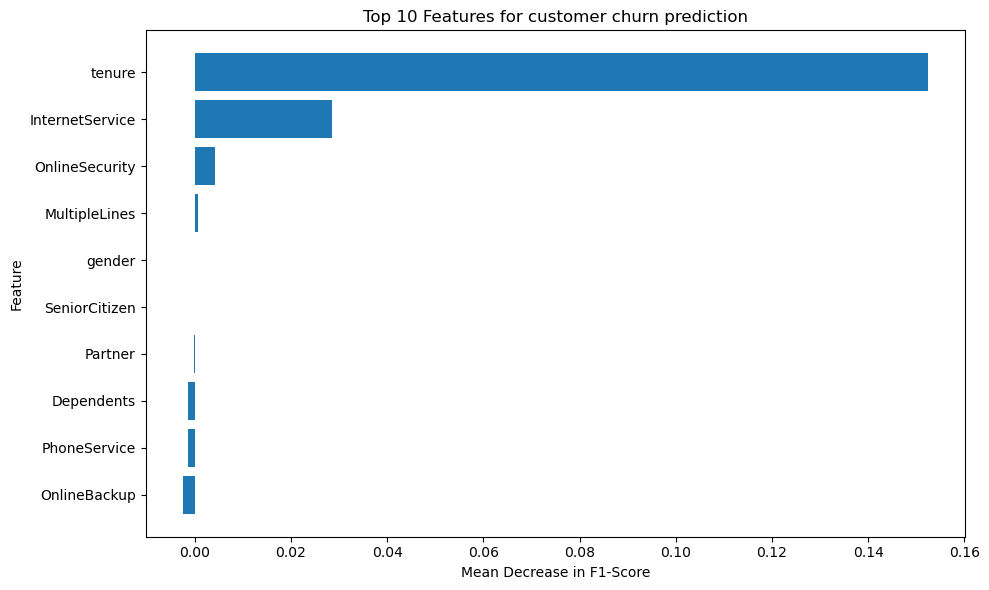

In [187]:
#Calculate feature importance

#create an F1-score for customers who churn
churn_f1_scorer = make_scorer(
    f1_score,
    pos_label='Yes'
)

#calculate permutation importance
perm_importance = permutation_importance(
    balanced_lr_model,
    X_test,
    y_test,
    scoring=churn_f1_scorer,
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

#create a feature importance DataFrame
feature_importance = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': perm_importance.importances_mean
})

#sort features by importance
features_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

#display the top 10 features
print('Top 10 Features for customers churn predicition')
print(feature_importance.head(10).round(4).to_string(index=False))

#visualize the top 10 features
top_features = feature_importance.head(10).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10,6))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.xlabel('Mean Decrease in F1-Score')
plt.ylabel('Feature')
plt.title('Top 10 Features for customer churn prediction')
plt.tight_layout()
plt.show()

In [189]:
#display all features ranked by importance

print(feature_importance.round(4).to_string(index=False))

         Feature  Importance
          gender      0.0001
   SeniorCitizen     -0.0000
         Partner     -0.0002
      Dependents     -0.0014
          tenure      0.1524
    PhoneService     -0.0014
   MultipleLines      0.0006
 InternetService      0.0285
  OnlineSecurity      0.0041
    OnlineBackup     -0.0025
DeviceProtection     -0.0060
     TechSupport     -0.0021
     StreamingTV     -0.0031
 StreamingMovies     -0.0007
        Contract      0.0315
PaperlessBilling     -0.0040
   PaymentMethod      0.0033
  MonthlyCharges      0.0322
    TotalCharges      0.0003


In [193]:
#Cross Validation

from sklearn.model_selection import StratifiedKFold,cross_validate
from sklearn.metrics import(
    make_scorer,
    precision_score,
    recall_score,
    f1_score
)

#1.create 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

#2.define evaluation metrics
scoring = {
    'accuracy': 'accuracy',
    'precision': make_scorer(
        precision_score,
        pos_label='Yes'
    ),
    'recall': make_scorer(
        recall_score,
        pos_label='Yes'
    ),
    'f1': make_scorer(
        f1_score,
        pos_label='Yes'
    )
}

#3.evaluate the model using the training data
cv_results = cross_validate(
    balanced_lr_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

#4.display the results
print('5-Fold Cross_validation Results')
print('--------------------------------')

for metric in scoring:
    scores = cv_results[f'test_{metric}']

    print(
        f'{metric.capitalize()}: '
        f'{scores.mean():.4f} +/ {scores.std():.4f}'
    )

5-Fold Cross_validation Results
--------------------------------
Accuracy: 0.7485 +/ 0.0153
Precision: 0.5169 +/ 0.0189
Recall: 0.8013 +/ 0.0379
F1: 0.6283 +/ 0.0232


In [195]:
#Compare all three machine learning models

model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'Balanced Logistic Regression'
    ],
    'Accuracy':[
        accuracy,
        rf_accuracy,
        balanced_accuracy
    ],
    'Precision': [
        precision,
        rf_precision,
        balanced_precision
    ],
    'Recall': [
        recall,
        rf_recall,
        balanced_recall
    ],
    'F1-score': [
        f1,
        rf_f1,
        balanced_f1
    ]
})

print(model_comparison.sort_values(by='F1-score',ascending=False).round(4).to_string(index=False))

                       Model  Accuracy  Precision  Recall  F1-score
Balanced Logistic Regression    0.7381     0.5043  0.7834    0.6136
         Logistic Regression    0.8055     0.6572  0.5588    0.6040
               Random Forest    0.7828     0.6189  0.4733    0.5364


In [197]:
#save the final model

import joblib

#save the trained model and preprocessing pipeline
joblib.dump(
    balanced_lr_model,
    'churn_model.pkl'
)

print('Model saved successfully')

Model saved successfully


In [199]:
#check the file was saved

import os

if os.path.exists('churn_model.pkl'):
    print('churn_model.pkl exists!')
else:
    print('Model file not found.')

churn_model.pkl exists!


In [205]:
import os

print(os.getcwd())
print(os.listdir)

C:\Users\Pratik\Customer Churn Data Science Project
<built-in function listdir>


In [ ]:
!python -m streamlit run app.py